In [14]:
from common import *

In [15]:
np.random.seed(1234)

In [16]:
def to_states(x, low=0, high=1):
    state = np.digitize(x, (low, high))
    s0 = state[0]
    for i, s in enumerate(state):
        if s == 1:
            state[i] = s0
        elif s != s0:
            s0 = s
    return state / 2

def committor(x, low=0, high=1, bins=20):
    state = np.digitize(x, (low, high))  # 0 = A, 1 = in between, 2 = B
    # For each state whether it will end in A or B
    s0 = state[-1]
    for i, s in enumerate(state[::-1]):
        if s == 1:
            state[::-1][i] = s0
        elif s != s0:
            s0 = s
    # Probability of ending in B
    ends_in_B = (state == 2)
    statistic, bin_edges, _ = binned_statistic(x, ends_in_B, bins=bins)
    return edges_to_range(bin_edges), statistic

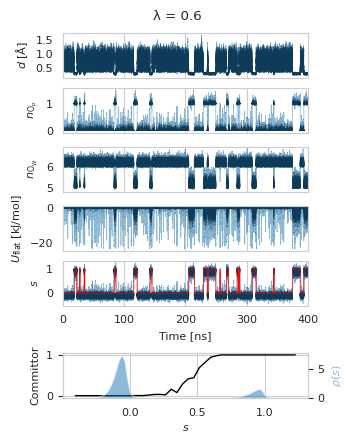

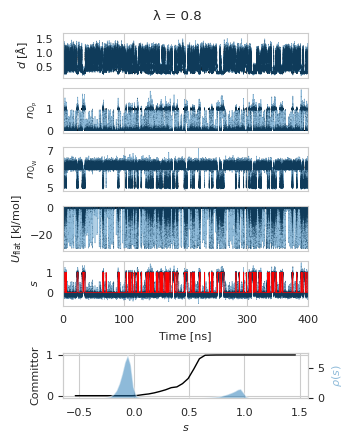

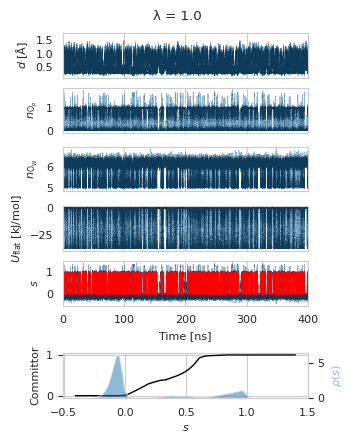

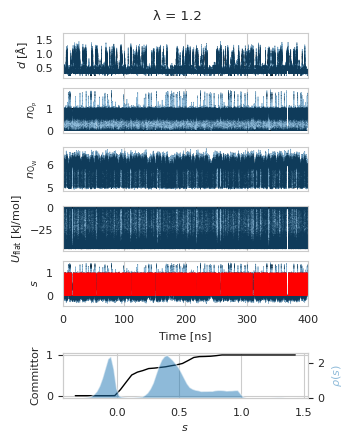

In [17]:
def plot_bias_timeseries(path, axarr):
    for ax in axarr[1:-1]:
        ax.sharex(axarr[0])
    for ax in axarr[0:-2]:
        ax.tick_params(labelbottom=False)

    colvar = read_plumed(f'{path}/COLVAR')
    t_range = colvar['time'] / 1000

    ax = axarr[0]
    y = colvar['dop']
    ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True)
    ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
    ax.set_ylabel("$d$ [Å]")
    ax.grid(axis='y')

    ax = axarr[1]
    y = colvar['cv.nb-0'] * 1.039661
    ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True)
    ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
    ax.set_ylabel("$n_\mathrm{O_P}$")
    ax.grid(axis='y')

    ax = axarr[2]
    y = colvar['cv.nc-0'] * 1.039661
    ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True)
    ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
    ax.set_ylabel("$n_\mathrm{O_W}$")
    ax.grid(axis='y')

    ax = axarr[3]
    y = colvar['bias.bias']
    ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True)
    ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
    ax.set_ylabel("$U_\mathrm{flat}$ [kJ/mol]")
    ax.grid(axis='y')

    ax = axarr[4]
    y = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
    state = to_states(y, low=0, high=0.8)
    ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True)
    ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
    ax.set_ylabel("$s$")
    ax.grid(axis='y')
    ax.plot(t_range, state, color='red', lw=0.5)
    ax.set_xlabel(r'Time [ns]')
    ax.set_xlim(t_range.min(), t_range.max())

    ax = axarr[5]
    y = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
    y_range, statistic = committor(y, low=0, high=0.8, bins=40)
    ax.plot(y_range, statistic, lw=1, color='black')
    ax.set_xlabel("$s$")
    ax.set_ylabel("Committor")
    ρ_y, y_edges = np.histogram(y, bins=80, density=True)
    y_range = edges_to_range(y_edges)
    ax = ax.twinx()
    ax.grid(False)
    fill = ax.fill_between(y_range, ρ_y, alpha=0.5)
    ax.set_ylabel("$ρ(s)$", color=fill.get_facecolor())
    ax.set_ylim(0, None)
    return axarr

#scalings = [0.6]
scalings = [0.6, 0.8, 1.0, 1.2]
for scaling in scalings:
    fig, axarr = plt.subplots(nrows=6, figsize=(8.7*cm, 11*cm))
    plot_bias_timeseries(PROJECT_DIR / f'kinetics/op_mMg_tip3p/{scaling:.1f}', axarr)
    fig.suptitle(f"λ = {scaling:.1f}")
    fig.get_layout_engine().set(h_pad=0.05)
    fig.savefig(f"figures/bias_timeseries_{scaling:.1f}.pdf")

### Comparison biased/unbiased/nMg

In [18]:
from scipy.stats import chi2

# Maximum likelihood estimate of rate (exponential decay)
def MLE_rate(times, censored_times=None, alpha=0.05):
    if censored_times is None:
        censored_times = []
    r = len(times)
    T = np.sum(times) + np.sum(censored_times)
    if r > 1:
        k = (r - 1) / T  # Unbiased MLE
    else:
        k = np.nan
    # (1-α)% confidence interval 
    k_low, k_high = chi2.ppf(alpha/2, 2*r) / (2 * T), chi2.ppf(1 - alpha/2, 2*r) / (2 * T)
    return k, (k_low, k_high)

μMg
vAB = nan 0.01—1.64
vBA = nan 0.01—2.02
nMg
vAB = 0.50 0.16—1.82
vBA = 8.91 2.76—32.18


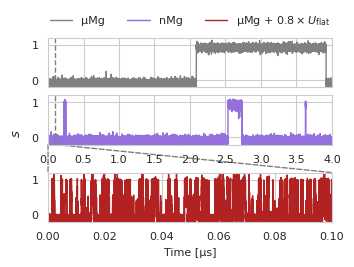

In [19]:
fig, axarr = plt.subplots(nrows=3, figsize=(8.7*cm, 6.5*cm))

handles, labels = [], []

# μMG

path = PROJECT_DIR / 'kinetics'
colvar = read_plumed(f'{path}/op_mMg_tip3p/0.0/cv.COLVAR').iloc[::10]
colvar['time'] /= 1000000
colvar['s'] = 0.5 * (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6)

t_range = colvar['time'].to_numpy()
states = to_states(colvar['s'], low=0, high=0.8)

times = np.concatenate([
    t_range[[0]],
    t_range[1:][states[:-1] != states[1:]],
    t_range[[-1]],
])
Δtimes = np.diff(times)
assert states[0] == 0
# Since states[0] should be 0 (unbound), first Δtime is A -> B (binding)
Δtimes_AB = Δtimes[:-1:2]
Δtimes_BA = Δtimes[1:-1:2]
# Last Δtime is right-censored
Δtimes_AB_censored = [Δtimes[-1]] if states[-1] == 0 else []
Δtimes_BA_censored = [Δtimes[-1]] if states[-1] == 1 else []

vAB, (vAB_low, vAB_high) = MLE_rate(Δtimes_AB, censored_times=Δtimes_AB_censored)
vBA, (vBA_low, vBA_high) = MLE_rate(Δtimes_BA, censored_times=Δtimes_BA_censored)

print("μMg")
print(f"vAB = {vAB:.2f} {vAB_low:.2f}—{vAB_high:.2f}")
print(f"vBA = {vBA:.2f} {vBA_low:.2f}—{vBA_high:.2f}")

ax = axarr[0]
line, = ax.plot(colvar['time'], colvar['s'], lw=1, color='gray')
handles.append(line)
labels.append("μMg")

ax.tick_params(labelbottom=False)
ax.set_xlim(0, 4)


# nMg

path = PROJECT_DIR / 'kinetics'
colvar = read_plumed(f'{path}/op_nMg_tip3p/0.0/cv.COLVAR').iloc[::10]
colvar['time'] /= 1000000
colvar['s'] = 0.5 * (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6)

t_range = colvar['time'].to_numpy()
states = to_states(colvar['s'], low=0, high=0.8)

times = np.concatenate([
    t_range[[0]],
    t_range[1:][states[:-1] != states[1:]],
    t_range[[-1]],
])
Δtimes = np.diff(times)
assert states[0] == 0
# Since states[0] should be 0 (unbound), first Δtime is A -> B (binding)
Δtimes_AB = Δtimes[:-1:2]
Δtimes_BA = Δtimes[1:-1:2]
# Last Δtime is right-censored
Δtimes_AB_censored = [Δtimes[-1]] if states[-1] == 0 else []
Δtimes_BA_censored = [Δtimes[-1]] if states[-1] == 1 else []

vAB, (vAB_low, vAB_high) = MLE_rate(Δtimes_AB, censored_times=Δtimes_AB_censored)
vBA, (vBA_low, vBA_high) = MLE_rate(Δtimes_BA, censored_times=Δtimes_BA_censored)

print("nMg")
print(f"vAB = {vAB:.2f} {vAB_low:.2f}—{vAB_high:.2f}")
print(f"vBA = {vBA:.2f} {vBA_low:.2f}—{vBA_high:.2f}")

ax = axarr[1]
line, = ax.plot(colvar['time'], colvar['s'], lw=1, color='mediumpurple')
handles.append(line)
labels.append("nMg")

# μMg + bias

path = PROJECT_DIR / 'kinetics'
colvar = read_plumed(f'{path}/op_mMg_tip3p/1.0/COLVAR')
colvar['time'] /= 1000000
colvar['s'] = 0.5 * (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6)
colvar['state'] = to_states(colvar['s'], low=0, high=0.8)

ax.set_xlim(0, 4)


ax = axarr[2]
line, = ax.plot(colvar['time'], colvar['s'], lw=1, color='firebrick')

handles.append(line)
labels.append(r"μMg + $0.8 \times U_\mathrm{flat}$")

ax.set_xlim(0, 0.100)
ax.set_xlabel("Time [μs]")

from matplotlib.patches import ConnectionPatch

ax0, ax1, ax2 = axarr[0], axarr[1], axarr[2]
ax0.axvline(0.100, color='gray', linestyle='dashed', lw=1)
ax1.axvline(0.100, color='gray', linestyle='dashed', lw=1)

ax1.add_artist(ConnectionPatch(xyA=(0, -0.2), xyB=(0, 1.2), 
                           coordsA="data", coordsB="data",
                           axesA=ax1, axesB=ax2, color="gray", lw=1, in_layout=False, ls='dashed', zorder=-10))
ax1.add_artist(ConnectionPatch(xyA=(0.100, -0.2), xyB=(0.100, 1.2), 
                           coordsA="data", coordsB="data",
                           axesA=ax1, axesB=ax2, color="gray", lw=1, in_layout=False, ls='dashed', zorder=-10))


for ax in axarr:
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylim(-0.2, 1.2)

axarr[0].legend(handles, labels, bbox_to_anchor=(0.5, 1), ncols=len(handles), loc='lower center', frameon=False)
fig.supylabel("$s$")
fig.savefig("figures/timeseries_comparison.pdf")

### nMg mechanism

(0.0, 4.19126)

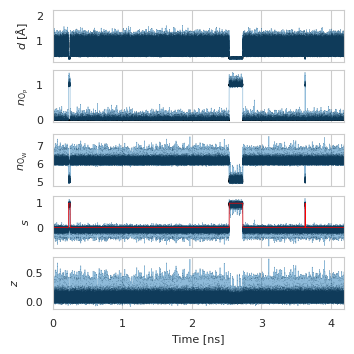

In [20]:
fig, axarr = plt.subplots(nrows=5, figsize=(8.7*cm, 8.7*cm))

for ax in axarr[1:]:
    ax.sharex(axarr[0])
for ax in axarr[0:-1]:
    ax.tick_params(labelbottom=False)


path = PROJECT_DIR / 'kinetics'
colvar = read_plumed(f'{path}/op_nMg_tip3p/0.0/cv.COLVAR')
t_range = colvar['time'] / 1000000

ax = axarr[0]
y = colvar['dop']
ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True)
ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
ax.set_ylabel("$d$ [Å]")
ax.grid(axis='y')

ax = axarr[1]
y = colvar['cv.nb-0'] * 1.039661
ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True)
ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
ax.set_ylabel("$n_\mathrm{O_P}$")
ax.grid(axis='y')

ax = axarr[2]
y = colvar['cv.nc-0'] * 1.039661
ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True)
ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
ax.set_ylabel("$n_\mathrm{O_W}$")
ax.grid(axis='y')

ax = axarr[3]
y = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
state = to_states(y, low=0, high=0.8)
ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True)
ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
ax.set_ylabel("$s$")
ax.grid(axis='y')
ax.plot(t_range, state, color='red', lw=0.5)

ax = axarr[4]
y = (colvar['cv.nb-0'] * 1.039661 + colvar['cv.nc-0'] * 1.039661 - 6) / 2
ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True)
ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
ax.set_ylabel("$z$")
ax.grid(axis='y')
ax.set_xlabel(r'Time [ns]')
ax.set_xlim(t_range.min(), t_range.max())


### Effect of bias on binding affinity

Bound state including the barrier: $s > 0$

In [21]:
scalings = np.array([0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2])

data = []
for scaling in scalings:
    colvar = read_plumed(PROJECT_DIR / f'kinetics/op_mMg_tip3p/{scaling:.1f}/COLVAR').assign(scaling=scaling)
    colvar['s'] = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
    data.append(colvar)
df = pd.concat(data)

bias = (df['cv.tot'].to_numpy()[:, None] * scalings) / RT
w = wham.wham(bias)
df['logW'] = w.logW
df['bound'] = df['s'] > 0


In [22]:
# Empirical
p_bound = df.groupby('scaling')['bound'].mean()
ΔG_bind = -RT * np.log(p_bound/(1-p_bound))

# Wham
bias = (df['cv.tot'].to_numpy() * scalings[:, None]) / RT
p_bound_wham = np.average(
    df['bound'].to_numpy() * np.ones_like(scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
ΔG_bind_wham = -RT * np.log(p_bound_wham / (1 - p_bound_wham))

# Wham
new_scalings = np.linspace(0, 1.2, 25)
bias = (df['cv.tot'].to_numpy() * new_scalings[:, None]) / RT
p_bound_wham = np.average(
    df['bound'].to_numpy() * np.ones_like(new_scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
ΔG_bind_wham_ext = -RT * np.log(p_bound_wham / (1 - p_bound_wham))


Excluding the barrier: $s \le 0$ and $s > 0.8$

In [23]:
# Empirical
df['bound_strict'] = df['s'] > 0.8
p_bound = df.groupby('scaling')['bound_strict'].mean()
p_unbound = 1 - df.groupby('scaling')['bound'].mean()
ΔG_bind_strict = -RT * np.log(p_bound/p_unbound)

# Wham
bias = (df['cv.tot'].to_numpy() * scalings[:, None]) / RT
p_bound_wham = np.average(
    df['bound_strict'].to_numpy() * np.ones_like(scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
p_unbound_wham = 1 - np.average(
    df['bound'].to_numpy() * np.ones_like(scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
ΔG_bind_strict_wham = -RT * np.log(p_bound_wham / p_unbound_wham)

# Wham
bias = (df['cv.tot'].to_numpy() * new_scalings[:, None]) / RT
p_bound_wham = np.average(
    df['bound_strict'].to_numpy() * np.ones_like(new_scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
p_unbound_wham = 1 - np.average(
    df['bound'].to_numpy() * np.ones_like(new_scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
ΔG_bind_strict_wham_ext = -RT * np.log(p_bound_wham / p_unbound_wham)

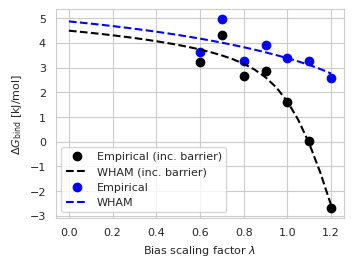

In [24]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

ax.scatter(ΔG_bind.index, ΔG_bind, color='black', label='Empirical (inc. barrier)')
ax.plot(new_scalings, ΔG_bind_wham_ext, color='black', ls='dashed', label='WHAM (inc. barrier)')
ax.scatter(ΔG_bind_strict.index, ΔG_bind_strict, color='blue', label='Empirical')
ax.plot(new_scalings, ΔG_bind_strict_wham_ext, color='blue', ls='dashed', label='WHAM')
ax.set_xlabel("Bias scaling factor $λ$")
ax.set_ylabel("$ΔG_\mathrm{bind}$ [kJ/mol]")
ax.legend(loc='lower left')
fig.savefig("figures/dGbind_bias.pdf")

### λ-wise MLE fit

In [25]:


data = []
for scaling in scalings:
    colvar = read_plumed(PROJECT_DIR / f'kinetics/op_mMg_tip3p/{scaling:.1f}/COLVAR')
    t_range = colvar['time'] / 1000
    y = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
    states = to_states(y, low=0, high=0.8)
    # Find transition times
    times = t_range[1:][states[:-1] != states[1:]]
    Δtimes = np.diff(times)
    assert states[0] == 0
    # Since states[0] should be 0 (unbound), first Δtime is 2->0 (unbinding)
    Δtimes_BA = Δtimes[::2]
    Δtimes_AB = Δtimes[1::2]

    vBA, (vBA_low, vBA_high) = MLE_rate(Δtimes_BA)
    vAB, (vAB_low, vAB_high) = MLE_rate(Δtimes_AB)

    bias = colvar['bias.bias']
    weights = np.exp(bias / RT)
    kish_ratio = np.sum(weights)**2 / np.sum(weights**2) / len(weights)    

    data.append({
        'scaling': scaling,
        'vAB': vAB,
        'vAB_low': vAB_low,
        'vAB_high': vAB_high,
        'vBA': vBA,
        'vBA_low': vBA_low,
        'vBA_high': vBA_high,
        'kish_ratio': kish_ratio,
    })
df = pd.DataFrame(data)
df

,scaling,vAB,vAB_low,vAB_high,vBA,vBA_low,vBA_high,kish_ratio
0,0.6,0.049422,0.030132,0.081514,0.210334,0.128239,0.346915,0.966305
1,0.7,0.076312,0.051844,0.112652,0.511972,0.350370,0.750158,0.966553
2,0.8,0.295507,0.240568,0.363229,0.991944,0.808435,1.217888,0.921084
3,0.9,0.661922,0.578357,0.757759,2.584361,2.258098,2.958541,0.893789
4,1.0,1.628873,1.488231,1.783011,4.278289,3.908888,4.683136,0.789342
5,1.1,3.044016,2.833675,3.270204,4.895297,4.557250,5.258794,0.599930
6,1.2,4.560364,4.245243,4.899226,3.184916,2.964981,3.421411,0.308849


### Global MLE including ΔG estimation from WHAM

$$
k(λ) = k_0e^{βλΔE^\ddagger}
$$
$$
k⁺(λ) = k(λ)e^{-β\frac{ΔG(λ)}{2}} = k_0e^{βλΔE^\ddagger}e^{-β\frac{ΔG(λ)}{2}} \\
k⁻(λ) = k(λ)e^{β\frac{ΔG(λ)}{2}} = k_0e^{βλΔE^\ddagger}e^{β\frac{ΔG(λ)}{2}}
$$
$$
p^±(t^±; k_0, ΔE^\ddagger, λ) = k^±(λ)e^{-k^±(λ)t^±}
$$


Log-likelihood for observation $t^±$
$$
\ell^±(k_0, ΔE^\ddagger, λ; t^±) = \ln k^±(λ) - k^±(λ)t^± = \ln k_0 + βλΔE^\ddagger ∓ β\frac{ΔG(λ)}{2} -  k_0e^{βλΔE^\ddagger}e^{∓β\frac{ΔG(λ)}{2}}t^±
$$

Total log-likelihood
$$
\ell\left(k_0, ΔE^\ddagger; \left\{(λ_k, \{t⁺_{k,i}\}^{n⁺_k}, \{t⁻_{k,j}\}^{n⁻_k})\right\}^K\right) = \sum_k^K \left[N_k\left(\ln k_0 + βλ_kΔE^\ddagger\right) - k_0e^{βλ_kΔE^\ddagger}\left(\sum_i^{n⁺_k}e^{-β\frac{ΔG(λ_k)}{2}}t⁺_{k,i} + \sum_j^{n⁻_k}e^{β\frac{ΔG(λ_k)}{2}}t⁻_{k,j}\right)\right] + \mathrm{const}
$$

$$
\frac{\partial\ell}{\partial k_0}(k_0, ΔE^\ddagger; X) = \sum_k^K \left[\frac{N_k}{k_0} - e^{βλ_kΔE^\ddagger}S_k\right]
$$

$$
\frac{\partial\ell}{\partial ΔE^\ddagger}(k_0, ΔE^\ddagger; X) = \sum_k^K \left[βλ_kN_k - k_0βλ_ke^{βλ_kΔE^\ddagger}S_k\right]
$$

$$
\frac{\partial\ell}{\partial k_0}(k_0, ΔE^\ddagger; X) = 0 \iff k_0 =  \frac{\sum_k^K N_k}{\sum_k^K e^{βλ_kΔE^\ddagger}S_k}
$$

$$
\frac{\partial\ell}{\partial ΔE^\ddagger}(k_0, ΔE^\ddagger; X) = 0 \iff k_0 = \frac{\sum_k λ_kN_k}{\sum_k λ_ke^{βλ_kΔE^\ddagger}S_k}
$$

$$
\iff \frac{\sum_k λ_kN_k}{\sum_k^K N_k}= \frac{\sum_k λ_ke^{βλ_kΔE^\ddagger}S_k}{\sum_k^K e^{βλ_kΔE^\ddagger}S_k}
$$

In [26]:
n_scalings = 3  # only use 3 first scaling values
n_bootstrap = 1000
n_blocks = 4

blocks = []
for scaling, ΔG in zip(scalings[:n_scalings+1], ΔG_bind_strict_wham[:n_scalings+1]):
    colvar = read_plumed(PROJECT_DIR / f'kinetics/op_mMg_tip3p/{scaling:.1f}/COLVAR')
    t_range = colvar['time'] / 1000
    y = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
    states = to_states(y, low=0, high=0.8)
    # Find transition times
    times = np.concatenate(
        (t_range[[0]], t_range[1:][states[:-1] != states[1:]])
    )
    Δtimes = np.diff(times)
    assert states[0] == 0
    # Since states[0] should be 0 (unbound), first Δtime is 0 -> 1 (binding)
    Δtimes_AB = Δtimes[::2]
    Δtimes_BA = Δtimes[1::2]
    for ab, ba in zip(np.array_split(Δtimes_AB, n_blocks), np.array_split(Δtimes_BA, n_blocks)):
        blocks.append((scaling, ΔG, ab, ba))


In [27]:
# Parameter estimation on all observations
S_k = []
λ_k = []
N_k = []

for block in blocks:
    scaling, ΔG, ab, ba = block
    S_k.append((ab * np.exp(-0.5 * ΔG / RT)).sum() + (ba * np.exp(0.5 * ΔG / RT)).sum())
    λ_k.append(scaling)
    N_k.append(len(ab) + len(ba))

S_k = np.array(S_k)
λ_k = np.array(λ_k)
N_k = np.array(N_k)

C = N_k.sum() / (λ_k * N_k).sum()

def loss(ΔE):
    return ((S_k * np.exp(ΔE * λ_k / RT)).sum() / (λ_k * S_k * np.exp(ΔE * λ_k / RT)).sum() - C)**2

res = minimize_scalar(loss)
ΔE = res.x
k0 = N_k.sum() / (S_k * np.exp(λ_k * ΔE / RT)).sum()
k0_on = k0 * np.exp(-ΔG_bind_strict_wham_ext[0]/2/RT)
k0_off = k0 * np.exp(ΔG_bind_strict_wham_ext[0]/2/RT)

# Error estimation by bootstrap on blocks of observations
bootstrap_distribution = []

for _ in range(n_bootstrap):
    S_k = []
    λ_k = []
    N_k = []

    inds = np.random.choice(len(blocks), size=len(blocks))

    for i in inds:
        scaling, ΔG, ab, ba = blocks[i]
        S_k.append((ab * np.exp(-0.5 * ΔG / RT)).sum() + (ba * np.exp(0.5 * ΔG / RT)).sum())
        λ_k.append(scaling)
        N_k.append(len(ab) + len(ba))
    
    S_k = np.array(S_k)
    λ_k = np.array(λ_k)
    N_k = np.array(N_k)

    C = N_k.sum() / (λ_k * N_k).sum()

    def loss(ΔE):
        return ((S_k * np.exp(ΔE * λ_k / RT)).sum() / (λ_k * S_k * np.exp(ΔE * λ_k / RT)).sum() - C)**2

    _res = minimize_scalar(loss)
    _ΔE = _res.x
    _k0 = N_k.sum() / (S_k * np.exp(λ_k * _ΔE / RT)).sum()
    _k0_on = _k0 * np.exp(-ΔG_bind_strict_wham_ext[0]/2/RT)
    _k0_off = _k0 * np.exp(ΔG_bind_strict_wham_ext[0]/2/RT)
    bootstrap_distribution.append((_ΔE, _k0, _k0_on, _k0_off))

ci = np.quantile(bootstrap_distribution, (0.025, 0.975), axis=0)

In [28]:
print("ΔE = ", f'{ΔE:.2E} ({ci[0,0]:.2E}-{ci[1,0]:.2E}) kJ/mol')
print("k0 = ", f'{k0:.2E} ({ci[0,1]:.2E}-{ci[1,1]:.2E}) ns⁻¹')
print("k0_on = ", f'{k0_on:.2E} ({ci[0,2]:.2E}-{ci[1,2]:.2E}) ns⁻¹')
print("k0_off = ", f'{k0_off:.2E} ({ci[0,3]:.2E}-{ci[1,3]:.2E}) ns⁻¹')


ΔE =  2.19E+01 (2.00E+01-2.39E+01) kJ/mol
k0 =  4.92E-04 (2.52E-04-9.18E-04) ns⁻¹
k0_on =  1.85E-04 (9.52E-05-3.46E-04) ns⁻¹
k0_off =  1.30E-03 (6.69E-04-2.43E-03) ns⁻¹


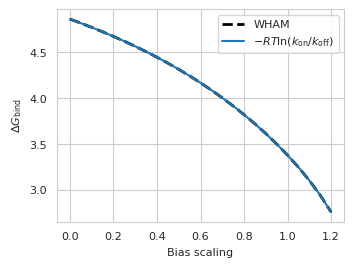

In [29]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

ax.plot(new_scalings, ΔG_bind_strict_wham_ext, label='WHAM', color='black', ls='dashed', lw=2)
ax.plot(new_scalings, -RT * np.log(
    (k0*np.exp(new_scalings * ΔE / RT) * np.exp(-0.5*ΔG_bind_strict_wham_ext/RT))
    / (k0*np.exp(new_scalings * ΔE / RT) * np.exp(0.5*ΔG_bind_strict_wham_ext/RT))
), label=r"$-RT\ln (k_\mathrm{on}/k_\mathrm{off})$")

ax.set_ylabel('$ΔG_\mathrm{bind}$')
ax.set_xlabel("Bias scaling")
ax.legend()
fig.savefig(f'figures/dGbind_kon_koff.pdf')

μMg
k_0_on = 1.85e-04 (9.52e-05 - 3.46e-04)
k_0_off = 1.30e-03 (6.69e-04 - 2.43e-03)
nMg
vAB = 5.04e-04 (1.56e-04 — 1.82e-03)
vBA = 8.91e-03 (2.76e-03 — 3.22e-02)


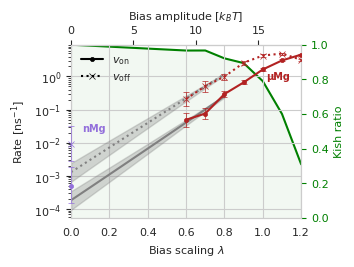

In [30]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

E = read_wsv(PROJECT_DIR / f'metad/op_mMg_tip3p/bias_params.wsv').iloc[0]['E'] / RT
ax.errorbar(df['scaling'], df['vAB'], yerr=(df['vAB'] - df['vAB_low'], df['vAB_high'] - df['vAB']), color='firebrick', zorder=10, capsize=2, marker='o', markersize=3, elinewidth=0.5, markeredgewidth=0.5)
ax.errorbar(df['scaling'], df['vBA'], yerr=(df['vBA'] - df['vBA_low'], df['vBA_high'] - df['vBA']), color='firebrick', linestyle='dotted', zorder=10, capsize=2, marker='x', markersize=4, elinewidth=0.5, markeredgewidth=0.5)

k_on_bs = []
k_off_bs = []
for _ΔE, _k0, _, _ in bootstrap_distribution:
    k_on_bs.append(_k0*np.exp(new_scalings * _ΔE / RT) * np.exp(-0.5*ΔG_bind_strict_wham_ext/RT))
    k_off_bs.append(_k0*np.exp(new_scalings * _ΔE / RT) * np.exp(0.5*ΔG_bind_strict_wham_ext/RT))

k_on = k0 * np.exp(new_scalings * ΔE / RT) * np.exp(-0.5 * ΔG_bind_strict_wham_ext / RT)
k_off = k0 * np.exp(new_scalings * ΔE / RT) * np.exp(0.5 * ΔG_bind_strict_wham_ext / RT)
k_on_p025, k_on_p975 = np.quantile(k_on_bs, (0.025, 0.975), axis=0)
k_off_p025, k_off_p975 = np.quantile(k_off_bs, (0.025, 0.975), axis=0)

print("μMg")
print(f"k_0_on = {k_on[0]:.2e} ({k_on_p025[0]:.2e} - {k_on_p975[0]:.2e})")
print(f"k_0_off = {k_off[0]:.2e} ({k_off_p025[0]:.2e} - {k_off_p975[0]:.2e})")

mask = new_scalings <= scalings[n_scalings-1]

ax.fill_between(new_scalings[mask], k_on_p025[mask], k_on_p975[mask], color='gray', alpha=0.3)
ax.fill_between(new_scalings[mask], k_off_p025[mask], k_off_p975[mask], color='gray', alpha=0.3)

ax.plot(new_scalings[mask], k_on[mask], color='gray')
ax.plot(new_scalings[mask], k_off[mask], color='gray', ls='dotted')

ax.set_yscale('log')
ax.set_xlabel("Bias scaling $λ$")
ax.set_xlim(0, df['scaling'].max())
ax.set_ylabel("Rate [ns$^{-1}$]")

# Add estimate for nMg

path = PROJECT_DIR / 'kinetics'
colvar = read_plumed(f'{path}/op_nMg_tip3p/0.0/cv.COLVAR').iloc[::10]
colvar['time'] /= 1000
colvar['s'] = 0.5 * (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6)

t_range = colvar['time'].to_numpy()
states = to_states(colvar['s'], low=0, high=0.8)

times = np.concatenate([
    t_range[[0]],
    t_range[1:][states[:-1] != states[1:]],
    t_range[[-1]],
])
Δtimes = np.diff(times)
assert states[0] == 0
# Since states[0] should be 0 (unbound), first Δtime is A -> B (binding)
Δtimes_AB = Δtimes[:-1:2]
Δtimes_BA = Δtimes[1:-1:2]
# Last Δtime is right-censored
Δtimes_AB_censored = [Δtimes[-1]] if states[-1] == 0 else []
Δtimes_BA_censored = [Δtimes[-1]] if states[-1] == 1 else []

vAB, (vAB_low, vAB_high) = MLE_rate(Δtimes_AB, censored_times=Δtimes_AB_censored)
vBA, (vBA_low, vBA_high) = MLE_rate(Δtimes_BA, censored_times=Δtimes_BA_censored)

print("nMg")
print(f"vAB = {vAB:.2e} ({vAB_low:.2e} — {vAB_high:.2e})")
print(f"vBA = {vBA:.2e} ({vBA_low:.2e} — {vBA_high:.2e})")

ax.errorbar([0], [vAB], yerr=[[vAB - vAB_low], [vAB_high - vAB]], clip_on=False, color='mediumpurple', zorder=10, capsize=2, marker='o', markersize=3, elinewidth=0.5, markeredgewidth=0.5)
ax.errorbar([0], [vBA], yerr=[[vBA - vBA_low], [vBA_high - vBA]], clip_on=False, color='mediumpurple', zorder=10, capsize=2, marker='x', markersize=4, elinewidth=0.5, markeredgewidth=0.5)

# Legend
ax.errorbar([], [], label=r'$v_\mathrm{on}$', color='black', zorder=10, capsize=2, marker='o', markersize=3, elinewidth=0.5, markeredgewidth=0.5)
ax.errorbar([], [],  label=r'$v_\mathrm{off}$', color='black', linestyle='dotted', zorder=10, capsize=2, marker='x', markersize=4, elinewidth=0.5, markeredgewidth=0.5)
legend = ax.legend(frameon=False)

ax.text(0.1, 0.5, "nMg", color='mediumpurple', fontweight='bold', fontsize=7, transform=ax.transAxes, ha='center')
ax.text(0.9, 0.8, "μMg", color='firebrick', fontweight='bold', fontsize=7, transform=ax.transAxes, ha='center')

secax = ax.secondary_xaxis('top', functions=(lambda x: E * x, lambda x: x / E))
secax.set_xlabel("Bias amplitude [$k_BT$]")

ax2 = ax.twinx()
ax2.grid(False)
ax2.yaxis.set_tick_params(labelcolor='green', color='green',
                         direction='out', which='major')
ax2.plot([0, *df['scaling']], [1, *df['kish_ratio']], label='Kish ratio', color='green')
ax2.fill_between([0, *df['scaling']], [1, *df['kish_ratio']], label='Kish ratio', facecolor='green', alpha=0.05)
ax2.set_ylim(0, 1)
ax2.set_zorder(-1)
ax2.set_ylabel("Kish ratio", color='green')
ax.patch.set_visible(False)


fig.savefig(f"figures/bias_kinetic_rates_mle{suffix}.pdf")

In [31]:
i, = np.argwhere(np.isclose(new_scalings, 1))[0]
print("At λ = 1")
print("k0_on = ", f'{k_on[i]:.2E} ({k_on_p025[i]:.2E}-{k_on_p975[i]:.2E}) ns⁻¹')
print("k0_off = ", f'{k_off[i]:.2E} ({k_off_p025[i]:.2E}-{k_off_p975[i]:.2E}) ns⁻¹')


At λ = 1
k0_on =  1.59E+00 (1.40E+00-1.86E+00) ns⁻¹
k0_off =  6.17E+00 (5.43E+00-7.21E+00) ns⁻¹


### Triuridine

In [32]:
colvar = read_plumed(PROJECT_DIR / 'kinetics/triuridine/op_mMg_tip3p/1.0/COLVAR')

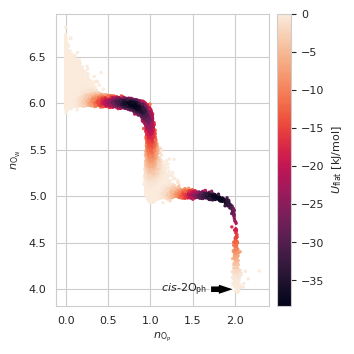

In [33]:
fig, (ax, cax) = plt.subplots(ncols=2, width_ratios=(15, 1), figsize=(8.7*cm, 8.7*cm))

sc = ax.scatter(colvar['cv.nb-0'] * 1.039661, colvar['cv.nc-0'] * 1.039661, c=colvar['bias.bias'], s=2, rasterized=True)
cbar = plt.colorbar(sc, cax=cax)
cax.set_ylabel(r'$U_\text{flat}$ [kJ/mol]')
ax.annotate(
    r'$\mathit{cis}$-$2\text{O}_\text{ph}$',
    xy=(2, 4),
    xytext=(-20, 0),
    ha='right',
    va='center',
    textcoords='offset points',
    arrowprops=dict(facecolor='black', width=5, headwidth=8),
)
ax.set_xlabel("$n_\mathrm{O_P}$")
ax.set_ylabel("$n_\mathrm{O_W}$")

fig.savefig('figures/triuridine_bias_nop_now.pdf')

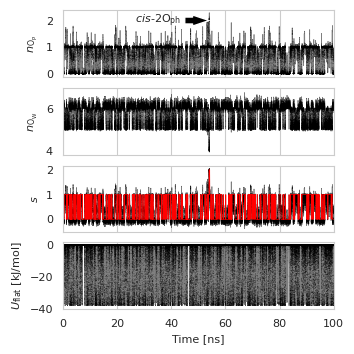

In [34]:
fig, axarr = plt.subplots(nrows=4, figsize=(8.7*cm, 8.7*cm))

for ax in axarr[1:]:
    ax.sharex(axarr[0])
for ax in axarr[0:-1]:
    ax.tick_params(labelbottom=False)

t_range = colvar['time'] / 1000

ax = axarr[0]
y = colvar['cv.nb-0'] * 1.039661
ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True, color='black')
ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
ax.set_ylabel("$n_\mathrm{O_P}$")
ax.grid(axis='y')

ax.annotate(
    r'$\mathit{cis}$-$2\text{O}_\text{ph}$',
    xy=(t_range[np.argmax(y)], 2),
    xytext=(-20, 0),
    ha='right',
    va='center',
    textcoords='offset points',
    arrowprops=dict(facecolor='black', width=5, headwidth=8),
)

ax = axarr[1]
y = colvar['cv.nc-0'] * 1.039661
ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True, color='black')
ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
ax.set_ylabel("$n_\mathrm{O_W}$")
ax.grid(axis='y')

ax = axarr[2]
y = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
state = to_states(y, low=0, high=0.8) + to_states(y, low=1, high=1.8)
ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True, color='black')
ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
ax.set_ylabel("$s$")
ax.grid(axis='y')
ax.plot(t_range, state, color='red', lw=0.5)

ax = axarr[3]
y = colvar['bias.bias']
ax.plot(t_range, y, lw=0.5, alpha=0.5, rasterized=True, color='black')
ax.scatter(t_range, y, s=1, alpha=0.5, c='k', rasterized=True, marker='.', edgecolors='none')
ax.set_ylabel("$U_\mathrm{flat}$ [kJ/mol]")
ax.grid(axis='y')


ax.set_xlabel(r'Time [ns]')
ax.set_xlim(0, 100)

fig.savefig('figures/triuridine_bias_timeseries.pdf')